## 1. Imports and Architecture Visualization

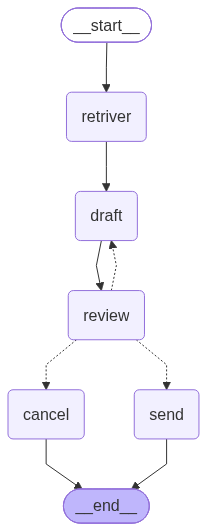

In [ ]:
import uuid
from IPython.display import Image, display
from agent import workflow, Command

# Display visual architecture of the compiled LangGraph workflow
try:
    display(Image(workflow.get_graph().draw_mermaid_png()))
except Exception as e:
    print("Mermaid PNG render unavailable:", e)
    print(workflow.get_graph().draw_mermaid())

## 2. Trigger Initial Email Request
Initiate the workflow with a user instruction. The workflow will extract details, generate the initial draft, and pause at the `review` node.

In [2]:
# A unique thread_id identifies this conversation session in the checkpointer
thread_id = str(uuid.uuid4())
config = {"configurable": {"thread_id": thread_id}}

user_request = (
    "I want to send an email to Alex Smith at alex.smith@example.com "
    "requesting an urgent project status update for Q3 deliverables."
)

# Invoke the workflow (will pause at review node)
result = workflow.invoke({"Question": user_request}, config=config)

# Inspect paused state
interrupts = result.get("__interrupt__")
if interrupts:
    print("\n>>> Workflow successfully interrupted for human review!")
    review_payload = interrupts[0].value
    print(f"Subject: {review_payload.get('subject')}")
    print(f"Body:\n{review_payload.get('body')}")


TO: Alex Smith <alex.smith@example.com>
SUBJECT: Urgent: Q3 Deliverables Status Update
--------------------------------------------------
BODY:
Hi Alex,

I hope you’re doing well.

Could you please provide an urgent status update on the Q3 deliverables? We need the latest progress, any blockers, and the expected completion timeline to ensure we stay on track.

Your prompt response would be greatly appreciated.

Best regards,
[Your Name]


>>> Workflow successfully interrupted for human review!
Subject: Urgent: Q3 Deliverables Status Update
Body:
Hi Alex,

I hope you’re doing well.

Could you please provide an urgent status update on the Q3 deliverables? We need the latest progress, any blockers, and the expected completion timeline to ensure we stay on track.

Your prompt response would be greatly appreciated.

Best regards,
[Your Name]


## 3. Human Feedback (Request a Rewrite)
Resume the paused workflow with human feedback. The router will guide the agent back to `draft` to revise the email.

In [3]:
# Give revision feedback
feedback = "Please make it much more concise and state that we need the update by 3:00 PM today."

revised_result = workflow.invoke(Command(resume=feedback), config=config)

# Inspect new revised draft
interrupts = revised_result.get("__interrupt__")
if interrupts:
    print("\n>>> Workflow paused again with revised draft:")
    revised_payload = interrupts[0].value
    print(f"Subject: {revised_payload.get('subject')}")
    print(f"Body:\n{revised_payload.get('body')}")


TO: Alex Smith <alex.smith@example.com>
SUBJECT: Urgent: Q3 Deliverables Status Update
--------------------------------------------------
BODY:
Hi Alex,

I hope you’re doing well.

Could you please provide an urgent status update on the Q3 deliverables? We need the latest progress, any blockers, and the expected completion timeline to ensure we stay on track.

Your prompt response would be greatly appreciated.

Best regards,
[Your Name]


TO: Alex Smith <alex.smith@example.com>
SUBJECT: Urgent: Q3 Deliverables Status Update
--------------------------------------------------
BODY:
Hi Alex,

Please provide an urgent status update on the Q3 deliverables by 3:00 PM today.

We need the latest progress, any blockers, and the expected completion timeline to ensure we stay on track.

Thank you,
[Your Name]


>>> Workflow paused again with revised draft:
Subject: Urgent: Q3 Deliverables Status Update
Body:
Hi Alex,

Please provide an urgent status update on the Q3 deliverables by 3:00 PM today

## 4. Approve and Send the Email
Resume the workflow with `'approve'`. The router routes execution to `send` to finalize.

In [4]:
# Approve the draft
final_result = workflow.invoke(Command(resume="approve"), config=config)

print("\n>>> Final Result:")
print("Response:", final_result.get("response"))
print("Recipient:", f"{final_result.get('recipient_name')} <{final_result.get('recipient_email')}>")
print("Subject:", final_result.get("subject"))
print("Feedback Log:", final_result.get("feedback"))


TO: Alex Smith <alex.smith@example.com>
SUBJECT: Urgent: Q3 Deliverables Status Update
--------------------------------------------------
BODY:
Hi Alex,

Please provide an urgent status update on the Q3 deliverables by 3:00 PM today.

We need the latest progress, any blockers, and the expected completion timeline to ensure we stay on track.

Thank you,
[Your Name]


[SEND] Dispatching email to Alex Smith <alex.smith@example.com> via smtplib...

[SMTP] Connecting to smtp.gmail.com:587...
[SMTP SUCCESS] Email successfully sent to alex.smith@example.com via smtp.gmail.com:587

>>> Final Result:
Response: Email sent successfully to Alex Smith (alex.smith@example.com) via SMTP.
Recipient: Alex Smith <alex.smith@example.com>
Subject: Urgent: Q3 Deliverables Status Update
Feedback Log: approved


## 5. Interactive Assistant Loop
Run an end-to-end interactive loop directly within Jupyter where you can input your prompt and interact with approvals and rewrites in real time.

In [5]:
def run_interactive_session(prompt: str):
    """Runs the email agent interactively until approved or cancelled."""
    sess_config = {"configurable": {"thread_id": str(uuid.uuid4())}}
    state = workflow.invoke({"Question": prompt}, config=sess_config)
    
    while state.get("__interrupt__"):
        int_info = state["__interrupt__"][0].value
        if isinstance(int_info, dict) and "subject" in int_info:
            print("\n" + "=" * 50)
            print(f"DRAFT SUBJECT: {int_info.get('subject')}")
            print("-" * 50)
            print(f"{int_info.get('body')}")
            print("=" * 50)
            user_input = input("\nEnter 'approve' to send, or enter feedback to rewrite: ")
        else:
            print("\n[Input Required]:", int_info)
            user_input = input("Enter details: ")
            
        state = workflow.invoke(Command(resume=user_input), config=sess_config)
        
    print("\n>>> Final Output:", state.get("response"))

# Example invocation:
run_interactive_session(
    "Send an email to Priya Sharma (priya@company.com) confirming our product demo tomorrow at 11 AM."
)


TO: Priya Sharma <priya@company.com>
SUBJECT: Confirmation: Product Demo Tomorrow at 11 AM
--------------------------------------------------
BODY:
Hi Priya,

I hope you’re doing well. I’m writing to confirm our product demo scheduled for tomorrow at 11 AM.

Please let me know if the time still works for you or if any adjustments are needed. I’ll be ready to walk through the key features and answer any questions you may have.

Looking forward to our session.

Best regards,
[Your Name]


DRAFT SUBJECT: Confirmation: Product Demo Tomorrow at 11 AM
--------------------------------------------------
Hi Priya,

I hope you’re doing well. I’m writing to confirm our product demo scheduled for tomorrow at 11 AM.

Please let me know if the time still works for you or if any adjustments are needed. I’ll be ready to walk through the key features and answer any questions you may have.

Looking forward to our session.

Best regards,
[Your Name]

TO: Priya Sharma <priya@company.com>
SUBJECT: Confirm

## 6. Direct SMTP Email Test (`smtplib`)

You can test the standalone `smtplib` sender directly without invoking the full graph workflow.

> **Setup Reminder:**
> Ensure `SMTP_EMAIL` and `SMTP_PASSWORD` are defined in your `.env` file.
> For Gmail, use an **App Password** (Google Account > Security > 2-Step Verification > App passwords), not your normal password.

In [6]:
from mailer import send_email_via_smtp

# Direct test of the smtplib email sender
success, status_msg = send_email_via_smtp(
    to_email="pendharisayama2612@gmail.com",
    subject="Direct SMTP Test from Email Agent",
    body="Hello,\n\nThis is a direct test of the smtplib integration in our Email Agent project!",
    recipient_name="Tester"
)

print("\nDelivery Status:", status_msg)


[SMTP] Connecting to smtp.gmail.com:587...
[SMTP SUCCESS] Email successfully sent to pendharisayama2612@gmail.com via smtp.gmail.com:587

Delivery Status: Email successfully sent to pendharisayama2612@gmail.com via smtp.gmail.com:587
